# 3. Source bias check

Injections all come from LLMail. Most normal emails come from Enron. A model could learn "LLMail vs Enron" instead of "attack vs no attack".

Test: a model that never sees the words, only the shape of the text (length, digits, capitals...). If it scores high, the dataset gives away the source, and text models must beat this score to prove they learned more.

Two runs: all data, then LLMail only (same source on both sides).

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd
from pyspark.ml import Pipeline
from pyspark.ml.classification import RandomForestClassifier
from pyspark.ml.evaluation import BinaryClassificationEvaluator
from pyspark.ml.feature import VectorAssembler
from pyspark.sql import functions as F

from src.spark_utils import get_spark

SEED = 42
spark = get_spark()
emails = spark.read.parquet(str(ROOT / "data" / "processed" / "emails.parquet"))

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/10/25 13:59:40 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


## Shape features

Eight numbers per email, no words. Ratios are per character.

In [2]:
def share(pattern):
    # Share of characters that match the pattern.
    return F.length(F.regexp_replace("text", pattern, "")) / F.length("text")


shape = emails.select(
    "label", "source", "split",
    F.length("text").alias("length"),
    F.size(F.split(F.trim("text"), r"\s+")).alias("words"),
    F.size(F.split("text", "\n")).alias("lines"),
    share("[^0-9]").alias("digits"),
    share("[^A-Z]").alias("capitals"),
    share(r"[^!-/:-@\[-`{-~]").alias("punctuation"),
    share(r"[^\s]").alias("spaces"),
    share(r"[\x00-\x7F]").alias("non_ascii"),
)
FEATURES = ["length", "words", "lines", "digits", "capitals", "punctuation", "spaces", "non_ascii"]
shape.groupBy("label").agg(*[F.round(F.avg(c), 3).alias(c) for c in FEATURES]).orderBy("label").toPandas()

,label,length,words,lines,digits,capitals,punctuation,spaces,non_ascii
0,0,1727.170,237.325,30.043,0.019,0.070,0.062,0.178,0.012
1,1,1837.278,230.995,27.000,0.009,0.057,0.071,0.147,0.031


## Model

Random forest: no scaling needed, and it finds thresholds like "shorter than 100 characters". AUC (area under the ROC curve): 0.5 = random guess, 1 = perfect.

In [3]:
pipeline = Pipeline(stages=[
    VectorAssembler(inputCols=FEATURES, outputCol="features"),
    RandomForestClassifier(labelCol="label", numTrees=100, maxDepth=8, seed=SEED),
])
auc = BinaryClassificationEvaluator(labelCol="label", metricName="areaUnderROC")


def run(data):
    model = pipeline.fit(data.filter("split = 'train'"))
    predictions = model.transform(data.filter("split = 'test'"))
    return model, predictions


model_all, pred_all = run(shape)
model_llmail, pred_llmail = run(shape.filter("source != 'enron'"))

pd.DataFrame({
    "AUC": [auc.evaluate(pred_all), auc.evaluate(pred_llmail)],
    "accuracy": [p.filter("prediction = label").count() / p.count() for p in (pred_all, pred_llmail)],
}, index=["all data", "LLMail only"]).round(3)

,AUC,accuracy
all data,0.933,0.853
LLMail only,0.880,0.820


Shape alone reaches AUC 0.93 on all data, and 0.88 inside LLMail. The shape of a text already says a lot, before any word.

So 0.93 is the bar: a text model must clearly beat it. Otherwise it learned little more than source and style.

## Who gets flagged

Share of test emails the model calls "injection", per source.

In [4]:
(
    pred_all.groupBy("source", "label")
    .agg(F.count("*").alias("emails"), F.round(F.avg("prediction") * 100, 1).alias("flagged as injection (%)"))
    .orderBy("label", "source")
    .toPandas()
)

,source,label,emails,flagged as injection (%)
0,challenge,0,43,55.8
1,enron,0,3684,4.3
2,llmail,0,2268,43.3
3,llmail,1,5968,90.0


Enron is easy: only 4 % flagged. The hard cases are LLMail normal emails (43 % flagged) and the challenge's legitimate emails (56 %, only 43 emails). They share the style of the attacks. Text models must make the difference there.

## What the model uses

Feature importance of the random forest, all data.

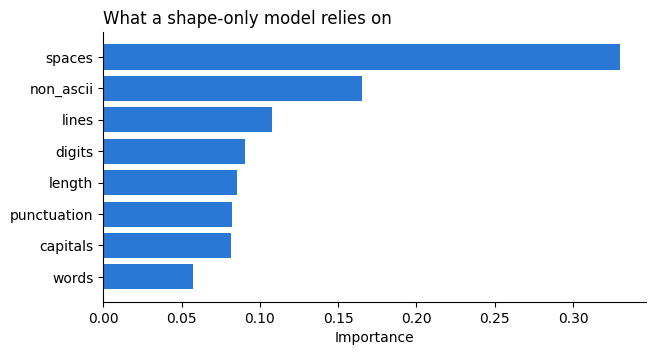

In [5]:
importance = pd.Series(model_all.stages[-1].featureImportances.toArray(), index=FEATURES).sort_values()
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.barh(importance.index, importance.values, color="#2a78d6")
ax.spines[["top", "right"]].set_visible(False)
ax.set_xlabel("Importance")
ax.set_title("What a shape-only model relies on", loc="left")
plt.show()

Top signal: share of spaces. Normal emails have more whitespace (17.8 % of characters vs 14.7 %). Then non-ASCII characters, almost absent from Enron. Both describe source and style, not the attack.

## Conclusion

The dataset leaks the source through shape. Bar for text models: AUC 0.93. Next notebooks compare every text model to it, and watch LLMail normal emails, the hard negatives.